# Exploratory Data Analysis of House Prices

## Introduction

Exploratory Data Analysis (EDA) is the process of analysing and understanding data using statistics and visualisations. In this project we explore the **Ames Housing dataset** to understand which factors drive house sale prices. This is an EDA-only project: **no machine learning model is built**.

## Objective

To analyse house prices using Python and understand which factors affect house sale prices, while practising the full EDA workflow.

## Guiding Questions

These questions were written down *before* touching the data. Every section below helps answer one or more of them.

1. How is `SalePrice` distributed? Is it skewed?
2. Which numerical features correlate most strongly with `SalePrice`?
3. Does overall quality (`OverallQual`) change price in a clear, ordered way?
4. Do some neighbourhoods consistently cost more than others?
5. Are there outliers, and are they errors or real but unusual sales?
6. Which columns have missing values, and which of those are not truly missing?

## Dataset

*House Prices: Advanced Regression Techniques* (Kaggle), file `train.csv`: 1460 rows and 81 columns.

## Tools Used

Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Jupyter Notebook.

## Notebook Structure

| Section | Content |
|---|---|
| 1 | Data loading and first look |
| 2 | Classification of variables |
| 3 | Descriptive statistics |
| 4 | Distribution analysis (univariate) |
| 5-7 | Correlation, scatter/pair plots, heatmap (bivariate and multivariate) |
| 8 | Outlier analysis |
| 9 | Data quality checks and cleaning |
| 10 | Final dashboard |
| 11 | Verifying the expected insights |
| 12 | Conclusions and limitations |

**Why cleaning comes at Step 9:** Steps 1-8 explore the *raw* data (`df`) so we can see the problems first (missing values, outliers). Step 9 builds a separate `df_clean`, and the dashboard in Step 10 uses `df_clean`. The raw `df` is never overwritten.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.ticker import FuncFormatter
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# One colour palette used across the whole notebook
BASE   = "#2a6f97"   # main colour
ACCENT = "#e07a5f"   # highlight colour (outliers, "No", etc.)
GREEN  = "#3a7d44"   # secondary highlight (median lines)
thousands = FuncFormatter(lambda x, _: f"{x/1000:,.0f}k")

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Dataset Loading and First Look

**What we do:** load the dataset and check its shape, data types and missing values.

In [2]:
from pathlib import Path

# Find train.csv beside the notebook or in the current working directory.
data_candidates = [Path('train.csv'), Path.cwd() / 'train.csv']
data_file = next((path for path in data_candidates if path.exists()), None)
if data_file is None:
    raise FileNotFoundError('train.csv was not found. Keep it in the same folder as this notebook.')

df = pd.read_csv(data_file)

print('Dataset loaded successfully from:', data_file.resolve())
print('Dataset Shape:', df.shape)
df.head()


Dataset loaded successfully from: /mnt/data/train.csv
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,...,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,...,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,...,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,...,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,...,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,...,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

#### Checking the missing values

In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    "missing": missing,
    "percent": (missing / len(df) * 100).round(2)
})
display(missing_table)

print(f"\nRows: {df.shape[0]}  |  Columns: {df.shape[1]}")
print("Total Columns with Missing Values:", len(missing_table))
print("Columns missing in more than 50% of rows:",
      missing_table[missing_table["percent"] > 50].index.tolist())

,missing,percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55



Rows: 1460  |  Columns: 81
Total Columns with Missing Values: 19
Columns missing in more than 50% of rows: ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']


### What we learned

- The dataset has **1460 rows and 81 columns**, a mix of numerical and categorical variables.
- **19 columns contain missing values.** A few of them (`PoolQC`, `MiscFeature`, `Alley`, `Fence`) are missing for most rows. A house that simply has no pool or no alley is very unlikely to be "unknown", so we suspect that in this dataset a missing value often means **"feature absent"**. We will confirm this in Step 9 instead of deleting these columns.
- `MasVnrType` shows a large number of missing values too. We will look at that column closely in Step 9, because pandas reads the text `"None"` as a missing value.

## 2. Classification of Variables

Variables are classified into three main types:

1. **Numerical** (continuous and discrete): numbers that can be measured or counted.
2. **Categorical** (nominal): groups with no natural order.
3. **Ordinal**: groups with a meaningful order (e.g. Poor < Fair < Typical < Good < Excellent).

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(exclude=np.number).columns

print("Total Numerical:", len(numeric_cols))
print("Total Categorical:", len(categorical_cols))
print("\nNumerical Columns:\n", list(numeric_cols))
print("\nCategorical Columns:\n", list(categorical_cols))

Total Numerical: 38
Total Categorical: 43

Numerical Columns:
 ['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
 ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electr

#### Ordinal variables

In [6]:
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]      # Poor < Fair < Typical < Good < Excellent

ordinal_map = {
    "ExterQual":   quality_order,
    "KitchenQual": quality_order,
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

print("Ordinal variables classified successfully!")
print(df["ExterQual"].dtype)
df[["ExterQual", "KitchenQual"]].head()

Ordinal variables classified successfully!
category


,ExterQual,KitchenQual
0,Gd,Gd
1,TA,TA
2,Gd,Gd
3,TA,Gd
4,Gd,Gd


#### Variable summary table

In [7]:
# OverallQual / OverallCond are stored as numbers (1-10) but are really ordinal.
ordinal_numeric = ["OverallQual", "OverallCond"]
# MSSubClass is a numeric *code* for building type, so it is really nominal.
nominal_numeric = ["MSSubClass"]

def var_type(col):
    if col in ordinal_map or col in ordinal_numeric:
        return "Ordinal"
    if col in nominal_numeric:
        return "Categorical (nominal, stored as number)"
    if col in numeric_cols:
        return "Numerical (discrete)" if df[col].nunique() <= 25 else "Numerical (continuous)"
    return "Categorical (nominal)"

variable_summary = pd.DataFrame({
    "column": df.columns,
    "type": [var_type(c) for c in df.columns],
    "unique_values": [df[c].nunique() for c in df.columns],
    "example_values": [", ".join(map(str, df[c].dropna().unique()[:3])) for c in df.columns],
})

print(variable_summary["type"].value_counts())
pd.set_option("display.max_rows", 100)
display(variable_summary)

type
Categorical (nominal)                      41
Numerical (continuous)                     20
Numerical (discrete)                       15
Ordinal                                     4
Categorical (nominal, stored as number)     1
Name: count, dtype: int64


,column,type,unique_values,example_values
0,Id,Numerical (continuous),1460,"1, 2, 3"
1,MSSubClass,"Categorical (nominal, stored as number)",15,"60, 20, 70"
2,MSZoning,Categorical (nominal),5,"RL, RM, C (all)"
3,LotFrontage,Numerical (continuous),110,"65.0, 80.0, 68.0"
4,LotArea,Numerical (continuous),1073,"8450, 9600, 11250"
5,Street,Categorical (nominal),2,"Pave, Grvl"
6,Alley,Categorical (nominal),2,"Grvl, Pave"
7,LotShape,Categorical (nominal),4,"Reg, IR1, IR2"
8,LandContour,Categorical (nominal),4,"Lvl, Bnk, Low"
9,Utilities,Categorical (nominal),2,"AllPub, NoSeWa"


### What we learned

- Most columns are either numerical or nominal categorical.
- **`OverallQual` (and `OverallCond`) look numerical but are ordinal**: a quality of 8 is *better* than 4, but not necessarily "twice as good". We keep them as numbers for plots and correlations, but interpret them as ordered grades.
- **`MSSubClass` is a numeric code** for the dwelling type, so averaging it would be meaningless. It is really nominal.
- The numeric "discrete vs continuous" split above uses a simple rule (25 or fewer distinct values = discrete), so it is a good guide, not an exact truth.
- `ExterQual` and `KitchenQual` are now ordered categoricals (Po < Fa < TA < Gd < Ex).

## 3. Descriptive Statistics

We summarise the centre (mean, median, mode) and spread (standard deviation, variance, range, IQR) of the data, plus its shape (skewness, kurtosis).

In [8]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


#### Statistical calculations

In [9]:
columns = ["SalePrice", "GrLivArea", "LotArea"]

for col in columns:
    s = df[col]
    print("\nStatistics for:", col)
    print("Mean:", round(s.mean(), 2))
    print("Median:", s.median())
    print("Mode:", s.mode()[0])
    print("Standard Deviation:", round(s.std(), 2))
    print("Variance:", round(s.var(), 2))
    print("Range:", s.max() - s.min())

    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    print("IQR:", Q3 - Q1)
    print("Skewness:", round(s.skew(), 3))
    print("Kurtosis:", round(s.kurt(), 3))

    if s.mean() > s.median():
        print("-> mean > median: RIGHT skewed")
    elif s.mean() < s.median():
        print("-> mean < median: LEFT skewed")
    else:
        print("-> mean = median: symmetric")


Statistics for: SalePrice
Mean: 180921.2
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.5
Variance: 6311111264.3
Range: 720100
IQR: 84025.0
Skewness: 1.883
Kurtosis: 6.536
-> mean > median: RIGHT skewed

Statistics for: GrLivArea
Mean: 1515.46
Median: 1464.0
Mode: 864
Standard Deviation: 525.48
Variance: 276129.63
Range: 5308
IQR: 647.25
Skewness: 1.367
Kurtosis: 4.895
-> mean > median: RIGHT skewed

Statistics for: LotArea
Mean: 10516.83
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.26
Variance: 99625649.65
Range: 213945
IQR: 4048.0
Skewness: 12.208
Kurtosis: 203.243
-> mean > median: RIGHT skewed


#### Categorical columns: counts and mode

In [10]:
for col in ["Neighborhood", "HouseStyle"]:
    print(f"\n{col}  (mode = {df[col].mode()[0]})")
    print(df[col].value_counts())


Neighborhood  (mode = NAmes)
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

HouseStyle  (mode = 1Story)
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64


In [11]:
gap = df["SalePrice"].mean() - df["SalePrice"].median()
print(f"SalePrice mean   : {df['SalePrice'].mean():,.0f}")
print(f"SalePrice median : {df['SalePrice'].median():,.0f}")
print(f"Gap (mean - median): {gap:,.0f}  ({gap / df['SalePrice'].median():.1%} of the median)")

SalePrice mean   : 180,921
SalePrice median : 163,000
Gap (mean - median): 17,921  (11.0% of the median)


### What we learned

- For all three columns, **mean > median** and skewness is positive, so each is **right skewed**: a small number of very expensive / very large houses pull the mean upwards while the median stays near the typical house.
- The gap between mean and median of `SalePrice` (printed above) tells us that **the median is the better "typical price"**, since the mean is dragged up by luxury homes.
- `LotArea` has an extreme kurtosis: a few huge lots make its tails very heavy.
- The most common neighbourhood and house style (the modes) are printed above. Some neighbourhoods have very few houses, which matters later when we compare averages.

## 4. Distribution Analysis

We use histograms with KDE, boxplots, a log transformation, Q-Q plots and countplots to see the shape of `SalePrice` and the key features.

#### SalePrice: histogram + KDE, boxplot and log-transformed histogram

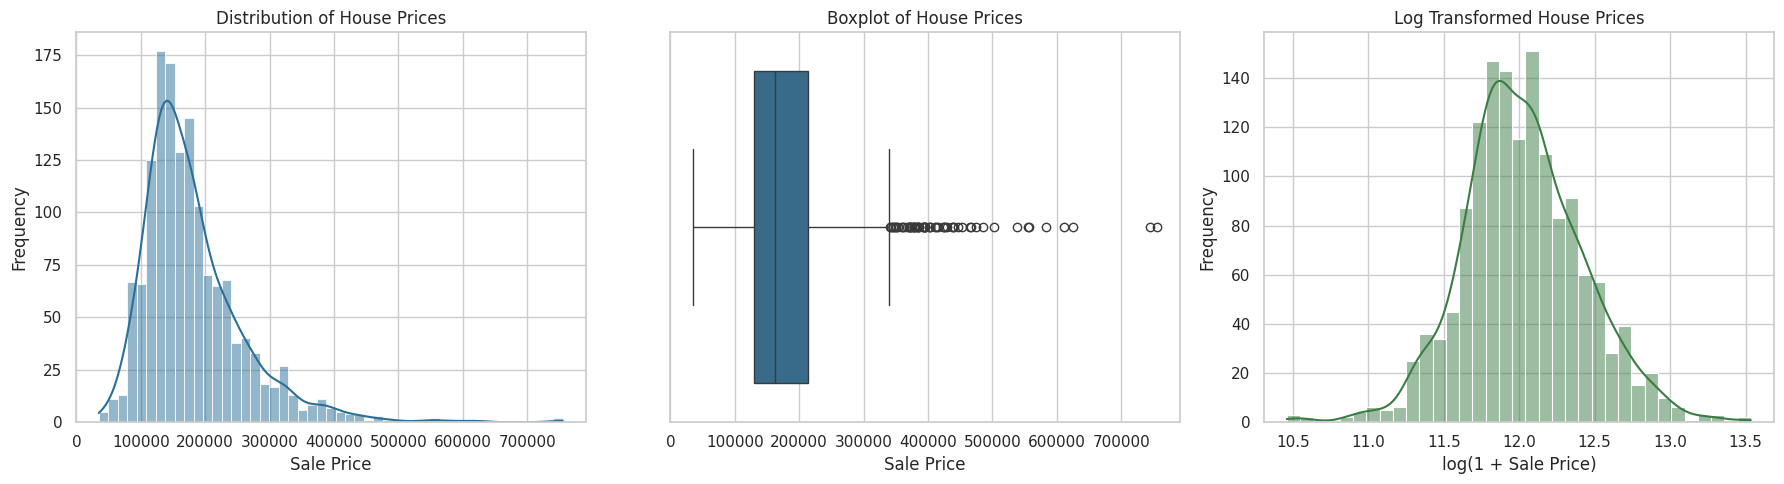

Original Skewness: 1.883
Log Skewness     : 0.121


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, color=BASE, ax=axes[0])
axes[0].set_title("Distribution of House Prices")
axes[0].set_xlabel("Sale Price")
axes[0].set_ylabel("Frequency")

sns.boxplot(x=df["SalePrice"], color=BASE, ax=axes[1])
axes[1].set_title("Boxplot of House Prices")
axes[1].set_xlabel("Sale Price")

sns.histplot(np.log1p(df["SalePrice"]), kde=True, color=GREEN, ax=axes[2])
axes[2].set_title("Log Transformed House Prices")
axes[2].set_xlabel("log(1 + Sale Price)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Original Skewness:", round(df["SalePrice"].skew(), 3))
print("Log Skewness     :", round(np.log1p(df["SalePrice"]).skew(), 3))

#### Q-Q plots: how close to a normal distribution?

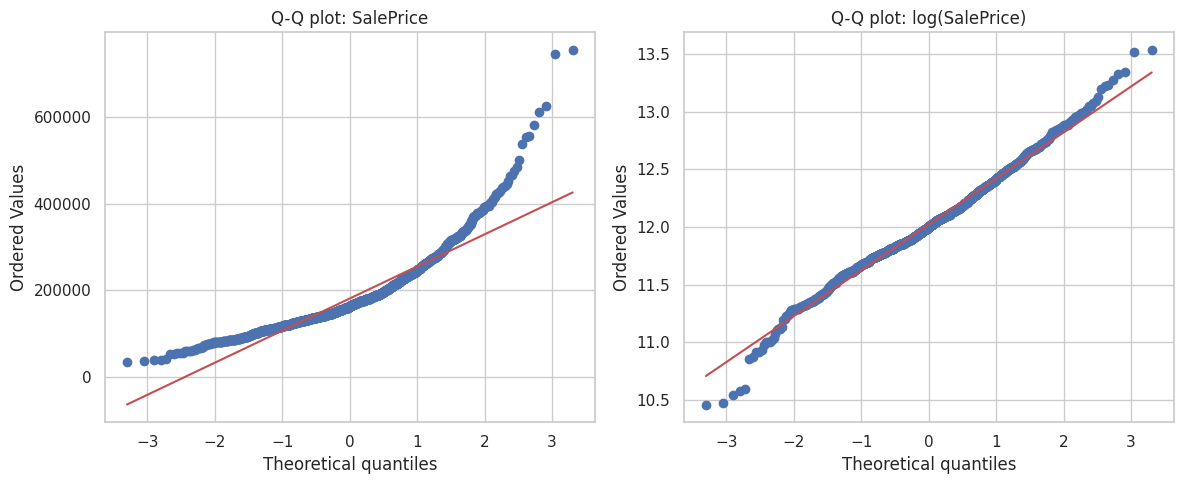

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stats.probplot(df["SalePrice"], dist="norm", plot=axes[0])
axes[0].set_title("Q-Q plot: SalePrice")

stats.probplot(np.log1p(df["SalePrice"]), dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: log(SalePrice)")

plt.tight_layout()
plt.show()

#### House quality vs price

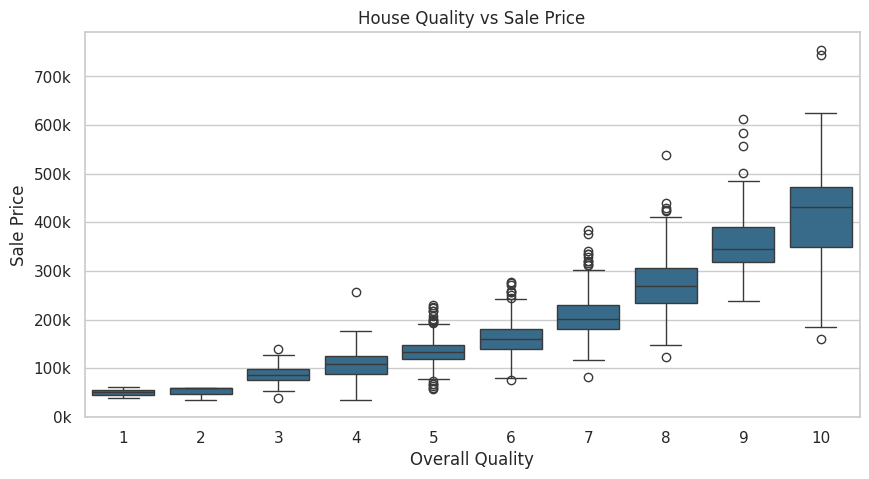

Median price rises with every quality step: True

Median price by quality:
 OverallQual
1      50150.0
2      60000.0
3      86250.0
4     108000.0
5     133000.0
6     160000.0
7     200141.0
8     269750.0
9     345000.0
10    432390.0
Name: SalePrice, dtype: float64

Spread (std) at quality 5 vs quality 10: 27107 vs 159785


In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", color=BASE)
plt.title("House Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.gca().yaxis.set_major_formatter(thousands)
plt.show()

q_median = df.groupby("OverallQual")["SalePrice"].median()
q_std    = df.groupby("OverallQual")["SalePrice"].std()
print("Median price rises with every quality step:", q_median.is_monotonic_increasing)
print("\nMedian price by quality:\n", q_median)
print("\nSpread (std) at quality 5 vs quality 10:",
      round(q_std.loc[5]), "vs", round(q_std.loc[10]))

#### Neighbourhood vs price

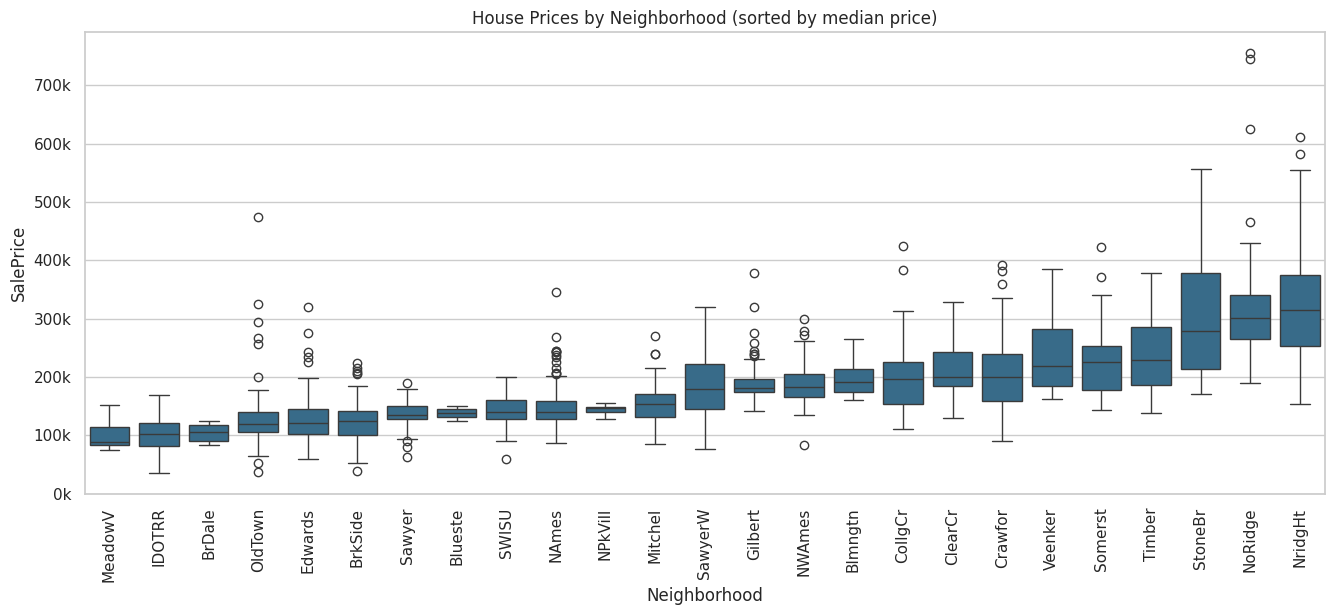

Cheapest 3 neighbourhoods (median):
                 median  count
Neighborhood                 
MeadowV        88000.0     17
IDOTRR        103000.0     37
BrDale        106000.0     16

Most expensive 3 neighbourhoods (median):
                 median  count
Neighborhood                 
StoneBr       278000.0     25
NoRidge       301500.0     41
NridgHt       315000.0     77

Median price ratio, most expensive / cheapest: 3.6x


In [15]:
order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

plt.figure(figsize=(16, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=order, color=BASE)
plt.title("House Prices by Neighborhood (sorted by median price)")
plt.xticks(rotation=90)
plt.gca().yaxis.set_major_formatter(thousands)
plt.show()

nb = df.groupby("Neighborhood")["SalePrice"].agg(["median", "count"]).sort_values("median")
print("Cheapest 3 neighbourhoods (median):\n", nb.head(3))
print("\nMost expensive 3 neighbourhoods (median):\n", nb.tail(3))
print(f"\nMedian price ratio, most expensive / cheapest: {nb['median'].iloc[-1] / nb['median'].iloc[0]:.1f}x")

#### Countplots

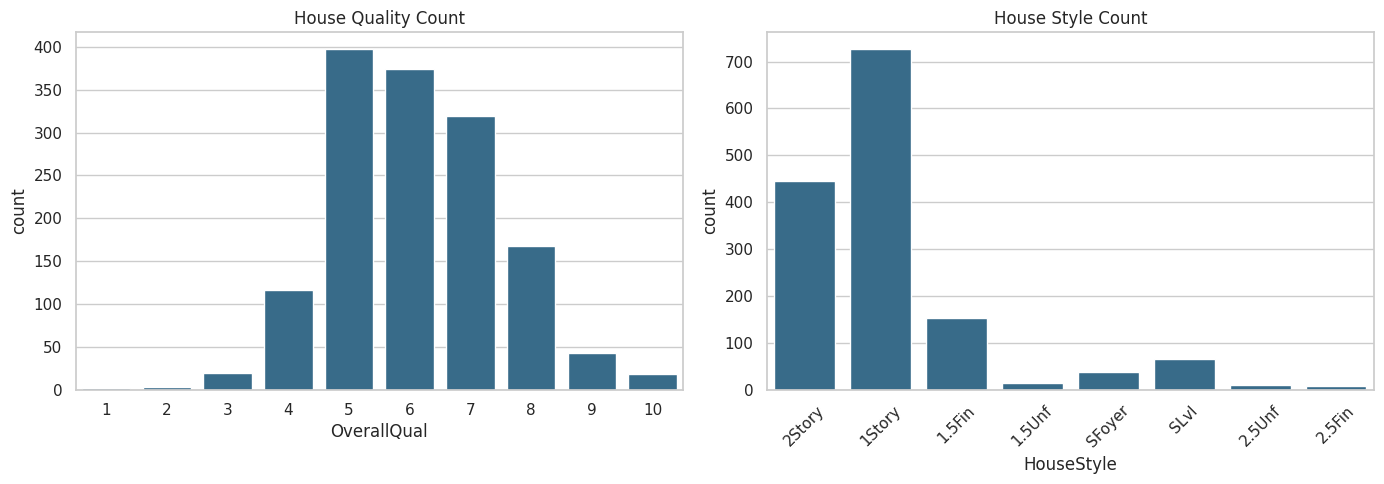

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="OverallQual", color=BASE, ax=axes[0])
axes[0].set_title("House Quality Count")

sns.countplot(data=df, x="HouseStyle", color=BASE, ax=axes[1])
axes[1].set_title("House Style Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### What we learned

1. **`SalePrice` is right skewed** (positive skewness, a long tail of expensive houses, many boxplot outliers on the high side).
2. **A log transform makes it close to normal**: skewness drops from about 1.9 to about 0.1, and the Q-Q plot points follow the straight line much more closely.
3. **Price rises with quality in a clear, ordered way**: the median increases at every step of `OverallQual`, and the spread (std) is much larger at the top grades than at the middle ones.
4. **Neighbourhood matters**: the most expensive neighbourhoods have a median several times higher than the cheapest ones, and their boxes barely overlap with the cheapest group.
5. Most houses are of middling quality (5-7), and one- and two-storey styles dominate the house-style counts, so extreme grades and rare styles rest on few observations.

## 5. Correlation and Covariance

- **Covariance** shows whether two variables move together, but its size depends on their units.
- **Correlation** (Pearson) rescales covariance to the range -1 to +1, so features can be compared fairly.

In this section we compute both and find the top 10 features correlated with `SalePrice`. (`Id` is just a row label, so we drop it.)

In [17]:
numeric_df = df.select_dtypes(include=np.number).drop(columns="Id")

cov_matrix  = numeric_df.cov()
corr_matrix = numeric_df.corr(method="pearson")

print("Covariance matrix shape :", cov_matrix.shape)
print("Correlation matrix shape:", corr_matrix.shape)

Covariance matrix shape : (37, 37)
Correlation matrix shape: (37, 37)


#### Top 10 correlated features

In [18]:
top_corr = corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False)

print("Top 10 Features Correlated with SalePrice (absolute value):")
print(top_corr.head(10).round(3))

print("\nSame features with their sign:")
print(corr_matrix["SalePrice"][top_corr.head(10).index].round(3))

Top 10 Features Correlated with SalePrice (absolute value):
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

Same features with their sign:
OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64


#### Covariance vs correlation for the top 3 features

In [19]:
top3 = top_corr.head(3).index

for col in top3:
    print("\nFeature:", col)
    print("Covariance with SalePrice :", f"{cov_matrix.loc[col, 'SalePrice']:,.2f}")
    print("Correlation with SalePrice:", round(corr_matrix.loc[col, "SalePrice"], 3))


Feature: OverallQual
Covariance with SalePrice : 86,904.13
Correlation with SalePrice: 0.791

Feature: GrLivArea
Covariance with SalePrice : 29,581,866.74
Correlation with SalePrice: 0.709

Feature: GarageCars
Covariance with SalePrice : 38,020.18
Correlation with SalePrice: 0.64


#### Spearman correlation for ordinal columns

In [20]:
# Spearman works on ranks, so it suits ordered grades.
# Ordered categoricals are turned into their rank codes (0 = Po ... 4 = Ex).
ordinal_check = pd.DataFrame({
    "OverallQual": df["OverallQual"],
    "ExterQual":   df["ExterQual"].cat.codes,
    "KitchenQual": df["KitchenQual"].cat.codes,
    "SalePrice":   df["SalePrice"],
})

spearman = ordinal_check.corr(method="spearman")["SalePrice"].drop("SalePrice")
pearson_oq = df["OverallQual"].corr(df["SalePrice"])
print("Spearman correlation with SalePrice:\n", spearman.round(3))
print("\nOverallQual: Pearson =", round(pearson_oq, 3), "| Spearman =", round(spearman["OverallQual"], 3))

Spearman correlation with SalePrice:
 OverallQual    0.810
ExterQual      0.684
KitchenQual    0.673
Name: SalePrice, dtype: float64

OverallQual: Pearson = 0.791 | Spearman = 0.81


#### Are the features correlated with each other?

In [21]:
ga_gc = df["GarageArea"].corr(df["GarageCars"])
print("Correlation between GarageArea and GarageCars:", round(ga_gc, 3))
print("GarageArea with SalePrice:", round(df["GarageArea"].corr(df["SalePrice"]), 3))
print("GarageCars with SalePrice:", round(df["GarageCars"].corr(df["SalePrice"]), 3))

Correlation between GarageArea and GarageCars: 0.882
GarageArea with SalePrice: 0.623
GarageCars with SalePrice: 0.64


### What we learned

- Covariance values are huge and sit on very different scales, so they cannot be compared across features. Correlation is on a common -1 to +1 scale, which is why it is better for ranking features.
- The top correlates (printed above) are led by **`OverallQual` and `GrLivArea`**. All of the top 10 are positive: bigger, better-built houses sell for more.
- The Spearman correlations for the ordinal grades are also strong, confirming that quality grades relate to price in a consistent *ordered* way, not only linearly.
- **Correlation is not causation.** Classic example: ice-cream sales and drowning both rise in summer, but one does not cause the other. A house with higher quality is often also bigger and in a better area, so we cannot say quality *alone* raises the price.
- **Features also correlate with each other (multicollinearity).** `GarageArea` and `GarageCars` are strongly correlated (printed above) because bigger garages hold more cars, so they carry mostly the *same* information. They should not be counted as two independent reasons for a higher price.

## 6. Scatter Plots and Pair Plots

Scatter plots show the relationship between two numerical variables and make unusual points easy to spot. Pair plots show many pairs at once.

#### Living area vs sale price (unusual houses highlighted)

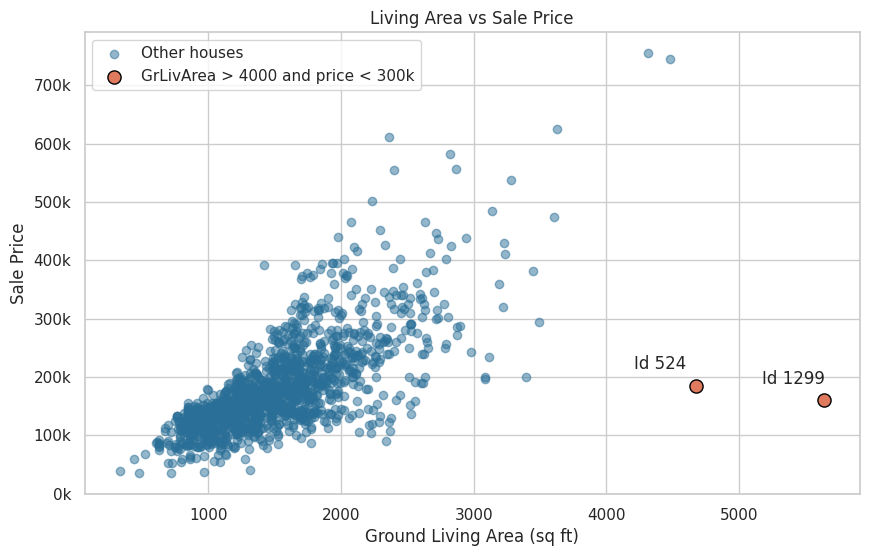

In [22]:
unusual = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)

plt.figure(figsize=(10, 6))
plt.scatter(df.loc[~unusual, "GrLivArea"], df.loc[~unusual, "SalePrice"],
            color=BASE, alpha=0.5, label="Other houses")
plt.scatter(df.loc[unusual, "GrLivArea"], df.loc[unusual, "SalePrice"],
            color=ACCENT, s=90, edgecolor="black", label="GrLivArea > 4000 and price < 300k")

for _, row in df[unusual].iterrows():
    plt.annotate(f"Id {int(row['Id'])}", (row["GrLivArea"], row["SalePrice"]),
                 xytext=(-45, 12), textcoords="offset points")

plt.title("Living Area vs Sale Price")
plt.xlabel("Ground Living Area (sq ft)")
plt.ylabel("Sale Price")
plt.gca().yaxis.set_major_formatter(thousands)
plt.legend()
plt.show()

#### Basement area vs sale price

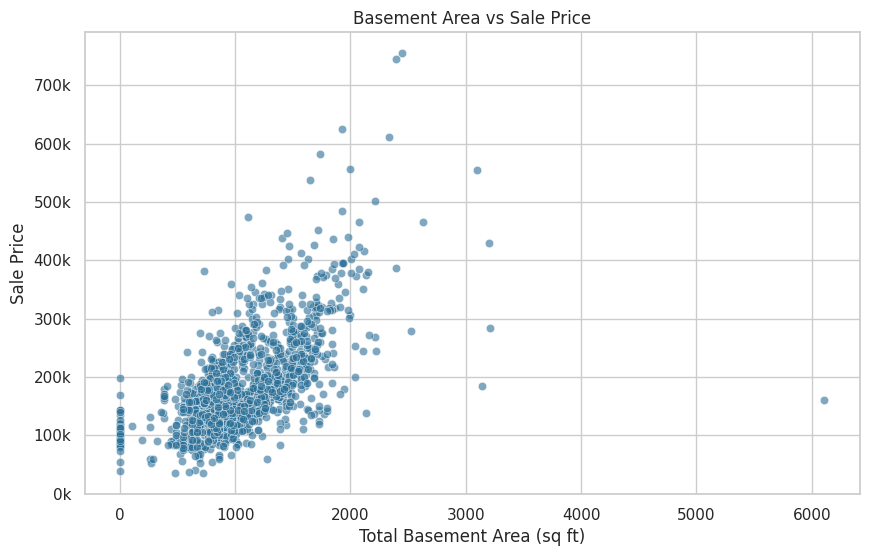

In [23]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", color=BASE, alpha=0.6)
plt.title("Basement Area vs Sale Price")
plt.xlabel("Total Basement Area (sq ft)")
plt.ylabel("Sale Price")
plt.gca().yaxis.set_major_formatter(thousands)
plt.show()

#### Year built vs sale price

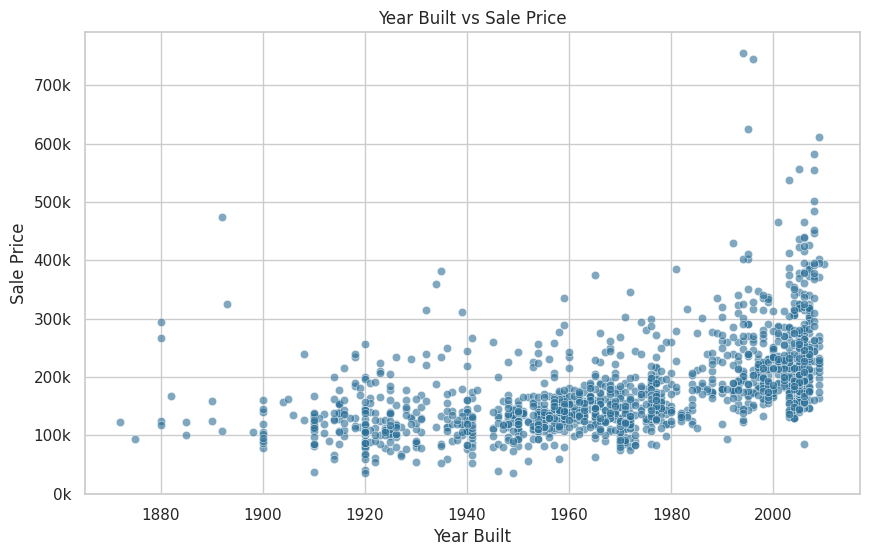

In [24]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", color=BASE, alpha=0.6)
plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")
plt.gca().yaxis.set_major_formatter(thousands)
plt.show()

#### Pair plot (coloured by central air conditioning)

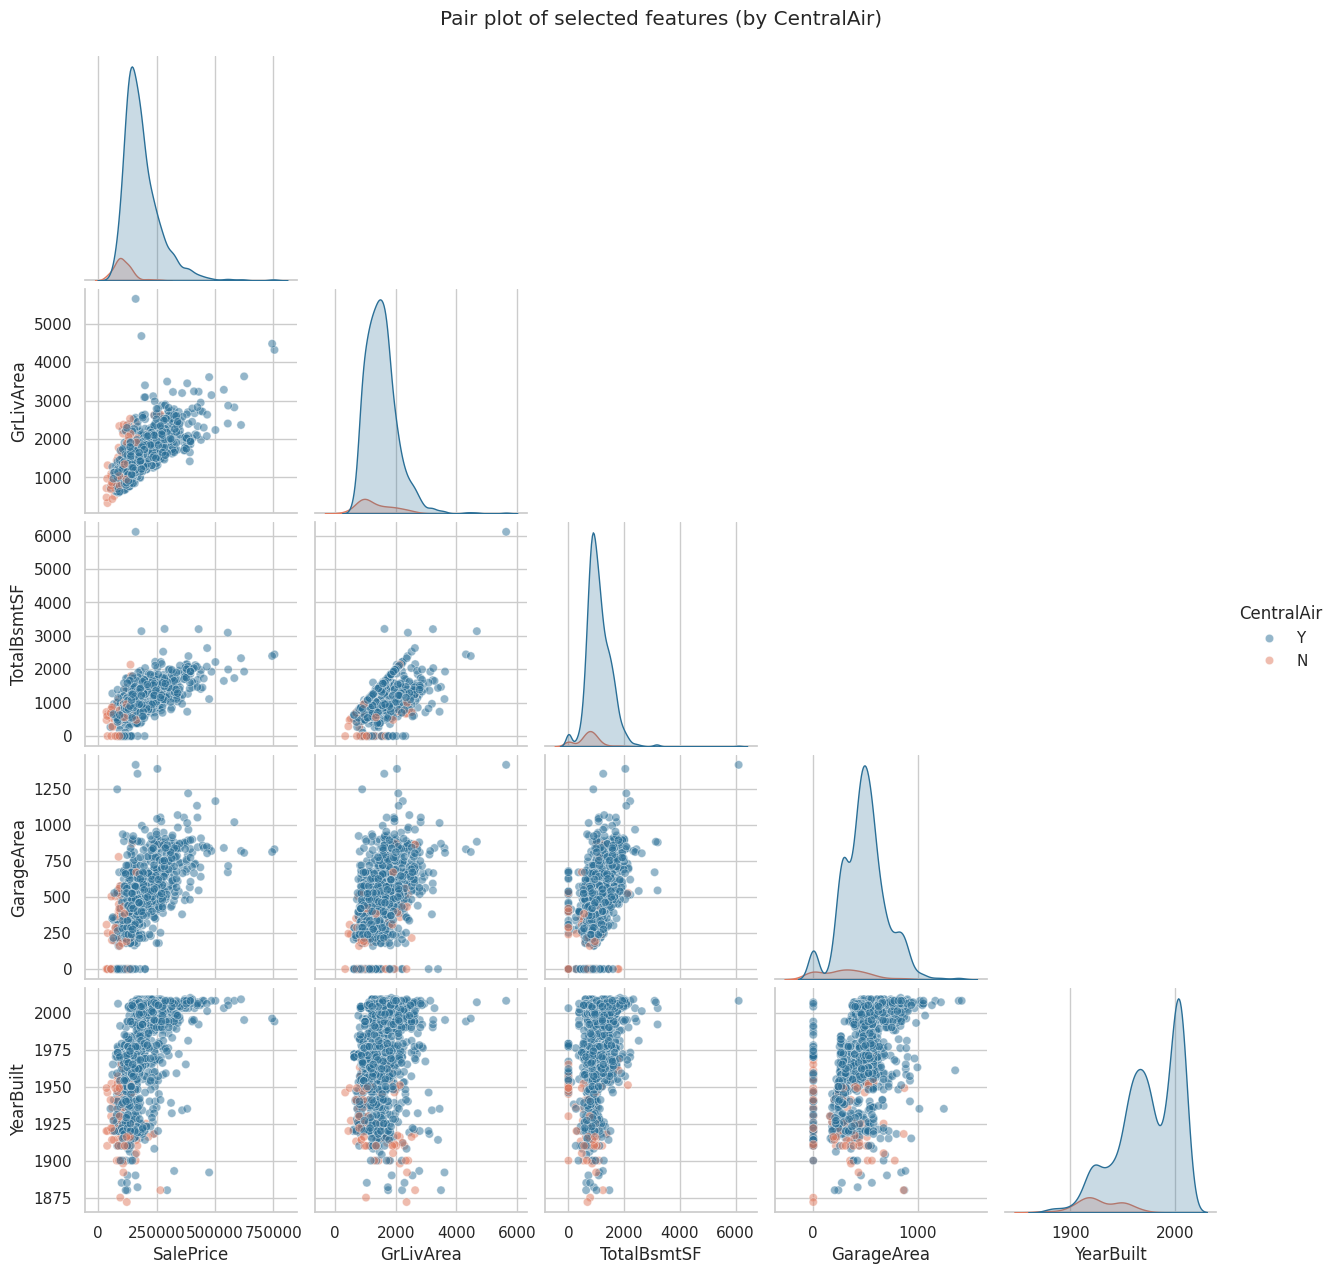

In [25]:
selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]

sns.pairplot(
    df[selected + ["CentralAir"]],
    hue="CentralAir",
    diag_kind="kde",
    palette={"Y": BASE, "N": ACCENT},
    plot_kws={"alpha": 0.5},
    corner=True,
)
plt.suptitle("Pair plot of selected features (by CentralAir)", y=1.02)
plt.show()

### What we learned

1. **Larger living areas generally mean higher prices**: the cloud rises from left to right.
2. **Basement area shows a similar rising relationship**, with a visible cluster at zero (houses with no basement).
3. **Newer houses tend to sell for higher prices**, but the relationship is looser than for area, so build year is a weaker predictor.
4. In the living-area plot **two houses stand out**: very large (over 4000 sq ft) but sold for a relatively low price. They sit far below the trend and will pull a fitted trend line down. We investigate them in Step 8.
5. In the pair plot, houses **without central air (N)** are concentrated among the older, cheaper homes, so central air partly acts as a marker for age and price level.

## 7. Correlation Heatmap

A heatmap puts many correlations in one picture. We use the top 10 features correlated with `SalePrice` and hide the duplicate upper half.

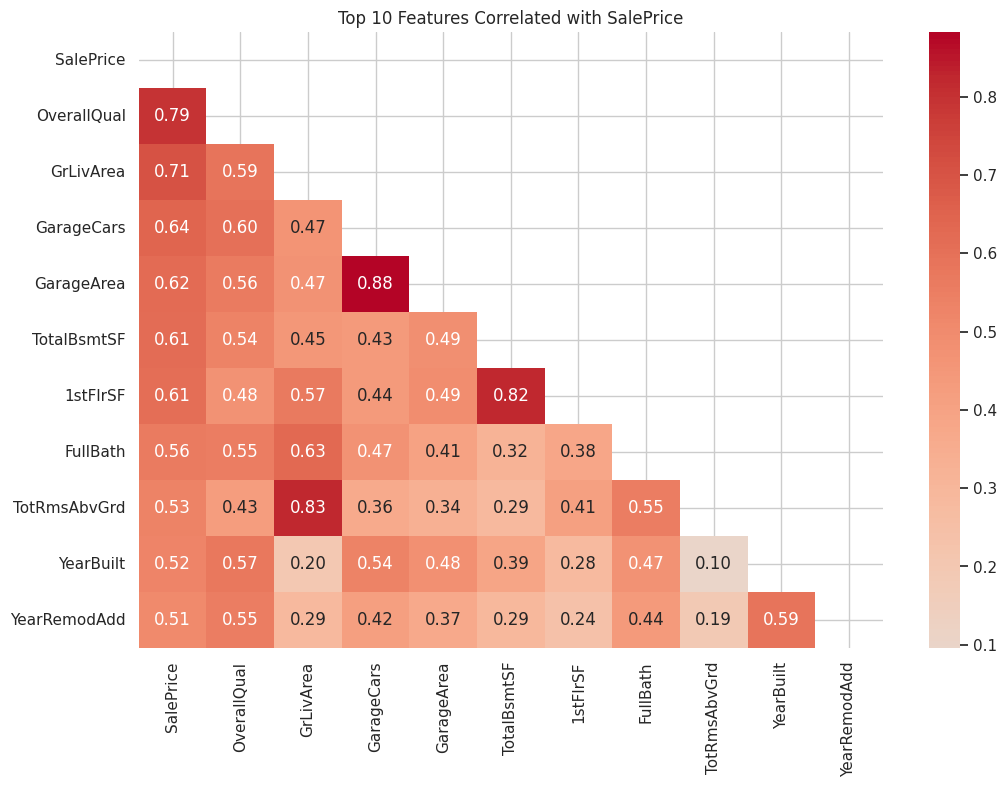

In [26]:
top10_features = ["SalePrice"] + top_corr.head(10).index.tolist()    # SalePrice first, then top 10 features
corr_top = df[top10_features].corr()

mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(12, 8))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=mask)
plt.title("Top 10 Features Correlated with SalePrice")
plt.show()

### What we learned

- The bottom row/column for `SalePrice` shows that the strongest relationships with price are with quality and size features.
- Several features are **strongly correlated with each other**, for example `GarageCars` with `GarageArea`, and `TotalBsmtSF` with `1stFlrSF`. They overlap in the information they give about a house.
- A heatmap only shows *linear* association. It does not prove cause and effect.

## 8. Outlier Detection

An outlier is a value very different from most others. We use two methods and compare them:

1. **IQR method**: flags values beyond 1.5 x IQR from the quartiles.
2. **Z-score method**: flags values more than 3 standard deviations from the mean.

In [27]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)].index


def zscore_outliers(series, threshold=3):
    clean = series.dropna()
    z = pd.Series(stats.zscore(clean), index=clean.index)
    return z[abs(z) > threshold].index

In [28]:
for column in ["GrLivArea", "SalePrice"]:
    iqr_result = iqr_outliers(df[column])
    z_result = zscore_outliers(df[column])

    print("\nColumn:", column)
    print("IQR Outliers     :", len(iqr_result))
    print("Z-score Outliers :", len(z_result))
    print("Common (overlap) :", len(set(iqr_result) & set(z_result)))
    print(f"Skewness: {df[column].skew():.2f}")


Column: GrLivArea
IQR Outliers     : 31
Z-score Outliers : 16
Common (overlap) : 16
Skewness: 1.37

Column: SalePrice
IQR Outliers     : 61
Z-score Outliers : 22
Common (overlap) : 22
Skewness: 1.88


#### Boxplots with outliers marked

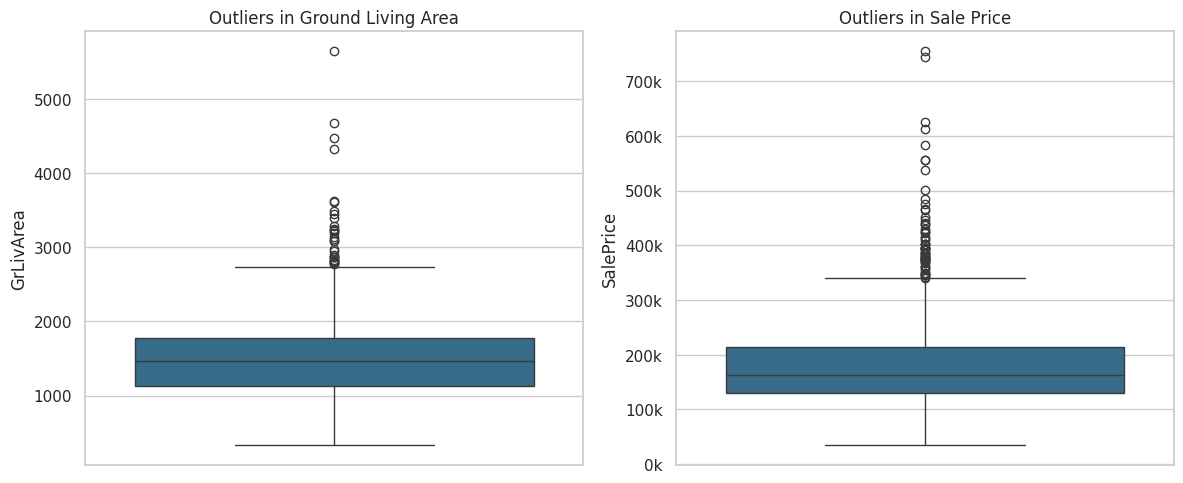

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["GrLivArea"], color=BASE, ax=axes[0])
axes[0].set_title("Outliers in Ground Living Area")

sns.boxplot(y=df["SalePrice"], color=BASE, ax=axes[1])
axes[1].set_title("Outliers in Sale Price")
axes[1].yaxis.set_major_formatter(thousands)

plt.tight_layout()
plt.show()

#### Scatter plot: which houses do the two methods flag?

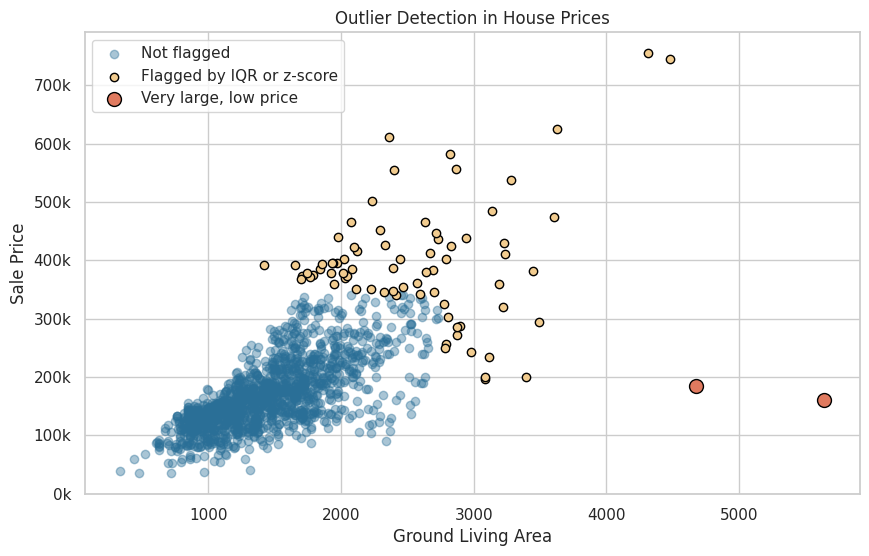

Total flagged houses: 77


In [30]:
flagged = set(iqr_outliers(df["GrLivArea"])) | set(iqr_outliers(df["SalePrice"])) \
        | set(zscore_outliers(df["GrLivArea"])) | set(zscore_outliers(df["SalePrice"]))
is_flagged = df.index.isin(flagged)
extreme = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)

plt.figure(figsize=(10, 6))
plt.scatter(df.loc[~is_flagged, "GrLivArea"], df.loc[~is_flagged, "SalePrice"],
            color=BASE, alpha=0.4, label="Not flagged")
plt.scatter(df.loc[is_flagged & ~extreme, "GrLivArea"], df.loc[is_flagged & ~extreme, "SalePrice"],
            color="#f2cc8f", edgecolor="black", label="Flagged by IQR or z-score")
plt.scatter(df.loc[extreme, "GrLivArea"], df.loc[extreme, "SalePrice"],
            color=ACCENT, s=100, edgecolor="black", label="Very large, low price")

plt.xlabel("Ground Living Area")
plt.ylabel("Sale Price")
plt.title("Outlier Detection in House Prices")
plt.gca().yaxis.set_major_formatter(thousands)
plt.legend()
plt.show()

print("Total flagged houses:", len(flagged))

#### Decision: error, unusual sale, or genuine sale?

In [31]:
extreme_idx = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)].index

print("Very large houses with a low price:")
display(df.loc[extreme_idx, ["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]])

print("Other very large houses (over 4000 sq ft) for comparison:")
display(df[(df["GrLivArea"] > 4000) & (df["SalePrice"] >= 300000)]
        [["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition"]])

Very large houses with a low price:


,Id,GrLivArea,SalePrice,OverallQual,Neighborhood,SaleCondition
523,524,4676,184750,10,Edwards,Partial
1298,1299,5642,160000,10,Edwards,Partial


Other very large houses (over 4000 sq ft) for comparison:


,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
691,692,4316,755000,10,Normal
1182,1183,4476,745000,10,Abnorml


### Decision and interpretation

- **Remove:** the very large, low-priced houses above. Their `SaleCondition` is **Partial** (the house was sold before it was completed), and a price far below what their size and quality would suggest is not a normal market sale. They are *unusual sales*, not typical houses, and they distort the size-price trend. They are removed in Step 9 and the decision is recorded there.
- **Keep:** all the other flagged points. The expensive houses and the large expensive houses are real sales at the top of the market. Removing them would hide real information, so we keep them and just remember that they stretch the right tail.
- **IQR vs z-score:** the IQR method flags more points than the z-score method on skewed variables. The reason is that the extreme values themselves **inflate the mean and standard deviation**, which pushes the z-score cutoff further out (the outliers "hide" each other). The quartiles used by IQR are not pulled by the extremes.
- Outliers should never be removed automatically: first ask whether each one is an error or a real, if unusual, sale.

## 9. Data Quality Checks

We build a separate cleaned copy, `df_clean`, and leave the raw `df` untouched. Checks:

1. Remove the unusual sales identified in Step 8.
2. Find duplicate rows.
3. Check categorical values for inconsistent labels.
4. Handle missing values, **documenting every decision**.
5. Check for impossible values.

In [32]:
# Step 8 decision: remove the very large, low-priced (Partial) sales
df_clean = df.drop(index=extreme_idx).copy()
print("Shape after removing unusual sales:", df_clean.shape)

# Duplicates: 'Id' is unique for every row, so compare all the OTHER columns.
dup_mask = df_clean.drop(columns="Id").duplicated()
print("Duplicate rows (ignoring Id):", dup_mask.sum())

if dup_mask.sum() > 0:
    df_clean = df_clean.loc[~dup_mask]
    print("Shape after removing duplicates:", df_clean.shape)

Shape after removing unusual sales: (1458, 81)
Duplicate rows (ignoring Id): 0


#### Checking categorical columns for inconsistent labels

In [33]:
# Remove extra spaces (ordered categoricals are skipped so the ordering is kept)
text_cols = [c for c in df_clean.select_dtypes(exclude=np.number).columns
             if not isinstance(df_clean[c].dtype, pd.CategoricalDtype)]

for c in text_cols:
    df_clean[c] = df_clean[c].str.strip()

# Casing / spacing variants of the same label inside one column
found = False
for c in text_cols:
    vals = df_clean[c].dropna().unique()
    if len({str(v).lower().replace(" ", "") for v in vals}) != len(vals):
        print("Case/space variants in", c, sorted(vals))
        found = True
if not found:
    print("No casing or spacing variants found inside any single column.")

# Same material spelled differently across two related columns?
e1 = set(df_clean["Exterior1st"].dropna())
e2 = set(df_clean["Exterior2nd"].dropna())
print("\nOnly in Exterior1st:", sorted(e1 - e2))
print("Only in Exterior2nd:", sorted(e2 - e1))

No casing or spacing variants found inside any single column.

Only in Exterior1st: ['BrkComm', 'CemntBd', 'WdShing']
Only in Exterior2nd: ['Brk Cmn', 'CmentBd', 'Other', 'Wd Shng']


In [34]:
# The same materials are spelled differently in Exterior2nd. Standardise to Exterior1st's spelling.
exterior_fix = {"CmentBd": "CemntBd", "Wd Shng": "WdShing", "Brk Cmn": "BrkComm"}
df_clean["Exterior2nd"] = df_clean["Exterior2nd"].replace(exterior_fix)

e2 = set(df_clean["Exterior2nd"].dropna())
print("Only in Exterior1st:", sorted(e1 - e2))
print("Only in Exterior2nd:", sorted(e2 - e1))

Only in Exterior1st: []
Only in Exterior2nd: ['Other']


#### Missing values: what does a missing value *mean*?

In this dataset the data description says that for many columns **NA means "the feature does not exist"** (no pool, no garage, no basement...). Those are not missing data, so we fill them with the label `"None"` instead of dropping them.

Also note: pandas treats the text `"None"` as a missing value when reading a CSV. `MasVnrType` really uses `"None"` as a category (no masonry veneer), so most of its "missing" values are genuine "None" houses.

In [35]:
decisions = []   # (column, number missing, what it means, action)

# 1) NA means the feature is absent -> "None"
absent = {
    "PoolQC": "no pool",          "MiscFeature": "no misc feature",
    "Alley": "no alley access",   "Fence": "no fence",
    "FireplaceQu": "no fireplace",
    "GarageType": "no garage",    "GarageFinish": "no garage",
    "GarageQual": "no garage",    "GarageCond": "no garage",
    "BsmtQual": "no basement",    "BsmtCond": "no basement",
    "BsmtExposure": "no basement", "BsmtFinType1": "no basement",
    "BsmtFinType2": "no basement",
}
for col, meaning in absent.items():
    n = df_clean[col].isnull().sum()
    df_clean[col] = df_clean[col].fillna("None")
    decisions.append((col, n, meaning, 'fill with "None"'))

# 2) Masonry veneer: "None" was read as NaN by pandas
n = df_clean["MasVnrType"].isnull().sum()
df_clean["MasVnrType"] = df_clean["MasVnrType"].fillna("None")
decisions.append(("MasVnrType", n, 'text "None" read as NaN (no veneer)', 'fill with "None"'))

n = df_clean["MasVnrArea"].isnull().sum()
df_clean["MasVnrArea"] = df_clean["MasVnrArea"].fillna(0)
decisions.append(("MasVnrArea", n, "no veneer -> area 0", "fill with 0"))

# 3) Electrical: a single genuinely missing value -> most common type
n = df_clean["Electrical"].isnull().sum()
df_clean["Electrical"] = df_clean["Electrical"].fillna(df_clean["Electrical"].mode()[0])
decisions.append(("Electrical", n, "truly missing", "fill with the mode"))

# 4) GarageYrBlt: houses without a garage have no garage year
bad = df_clean["GarageYrBlt"] > df_clean["YrSold"]            # impossible values (if any)
df_clean.loc[bad, "GarageYrBlt"] = np.nan
n = df_clean["GarageYrBlt"].isnull().sum()
df_clean["GarageYrBlt"] = df_clean["GarageYrBlt"].fillna(df_clean["YearBuilt"])
decisions.append(("GarageYrBlt", n, "no garage", "fill with YearBuilt (assumption; use with care)"))

# 5) LotFrontage: truly missing -> median of the same neighbourhood
n = df_clean["LotFrontage"].isnull().sum()
df_clean["LotFrontage"] = df_clean.groupby("Neighborhood")["LotFrontage"].transform(lambda x: x.fillna(x.median()))
df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(df_clean["LotFrontage"].median())
decisions.append(("LotFrontage", n, "truly missing", "median by Neighborhood (then overall median)"))

display(pd.DataFrame(decisions, columns=["column", "n_missing_filled", "meaning", "action"]))

,column,n_missing_filled,meaning,action
0,PoolQC,1452,no pool,"fill with ""None"""
1,MiscFeature,1404,no misc feature,"fill with ""None"""
2,Alley,1367,no alley access,"fill with ""None"""
3,Fence,1177,no fence,"fill with ""None"""
4,FireplaceQu,690,no fireplace,"fill with ""None"""
5,GarageType,81,no garage,"fill with ""None"""
6,GarageFinish,81,no garage,"fill with ""None"""
7,GarageQual,81,no garage,"fill with ""None"""
8,GarageCond,81,no garage,"fill with ""None"""
9,BsmtQual,37,no basement,"fill with ""None"""


In [36]:
# Safety net: anything still missing (there should be nothing)
left = df_clean.isnull().sum()
left = left[left > 0]
print("Still missing after documented decisions:", left.to_dict())

for c in left.index:
    if pd.api.types.is_numeric_dtype(df_clean[c]):
        df_clean[c] = df_clean[c].fillna(df_clean[c].median())
    else:
        df_clean[c] = df_clean[c].fillna("Unknown")

print("\nRemaining missing values:", df_clean.isnull().sum().sum())
print("Dataset Shape:", df_clean.shape)

Still missing after documented decisions: {}

Remaining missing values: 0
Dataset Shape: (1458, 81)


#### Ordinal columns in the cleaned data

In [37]:
# Now that 'absent' is a real label, build the ordered categories (None < Po < Fa < TA < Gd < Ex)
with_none = ["None"] + quality_order
ordinal_clean = {
    "ExterQual": quality_order, "ExterCond": quality_order,
    "HeatingQC": quality_order, "KitchenQual": quality_order,
    "BsmtQual": with_none, "BsmtCond": with_none,
    "FireplaceQu": with_none, "GarageQual": with_none,
    "GarageCond": with_none, "PoolQC": with_none,
}
for col, order in ordinal_clean.items():
    df_clean[col] = pd.Categorical(df_clean[col].astype(str), categories=order, ordered=True)

print("Ordinal columns with unrecognised labels:",
      {c: int(df_clean[c].isnull().sum()) for c in ordinal_clean if df_clean[c].isnull().sum() > 0})
print("Remaining missing values:", df_clean.isnull().sum().sum())

Ordinal columns with unrecognised labels: {}
Remaining missing values: 0


#### Check impossible values

In [38]:
print("YearBuilt greater than YrSold   :", (df_clean["YearBuilt"] > df_clean["YrSold"]).sum())
print("YearRemodAdd before YearBuilt   :", (df_clean["YearRemodAdd"] < df_clean["YearBuilt"]).sum())
print("GarageYrBlt greater than YrSold :", (df_clean["GarageYrBlt"] > df_clean["YrSold"]).sum())

for column in ["GrLivArea", "TotalBsmtSF", "LotArea", "GarageArea"]:
    print(column, "- negative values:", (df_clean[column] < 0).sum())

YearBuilt greater than YrSold   : 0
YearRemodAdd before YearBuilt   : 0
GarageYrBlt greater than YrSold : 0
GrLivArea - negative values: 0
TotalBsmtSF - negative values: 0
LotArea - negative values: 0
GarageArea - negative values: 0


### What we learned

- **No duplicate rows and no impossible values** were found (checks are kept so the notebook works on any version of the data).
- **Inconsistent labels were found**: the same exterior materials are spelled differently in `Exterior1st` and `Exterior2nd` (`CemntBd` vs `CmentBd`, `WdShing` vs `Wd Shng`, `BrkComm` vs `Brk Cmn`). Stripping spaces would not catch this, so a mapping dictionary was used.
- **Most "missing" values are not missing.** Pool, alley, fence, misc feature, fireplace, garage and basement columns are blank because the feature does not exist, so they were labelled `"None"` and kept. Only `LotFrontage` and `Electrical` are genuinely missing, and each has a documented fill rule.
- `MasVnrType` was another trap: pandas converted the real label `"None"` into NaN.
- Every decision is listed in the decision table above, and the raw `df` was never changed.

## 10. Final EDA Dashboard

The dashboard combines four visualisations from the cleaned data:

1. Average sale price by year built.
2. Top 10 neighbourhoods by average sale price.
3. Sale price distribution with mean and median.
4. Ground living area vs sale price, coloured by overall quality.

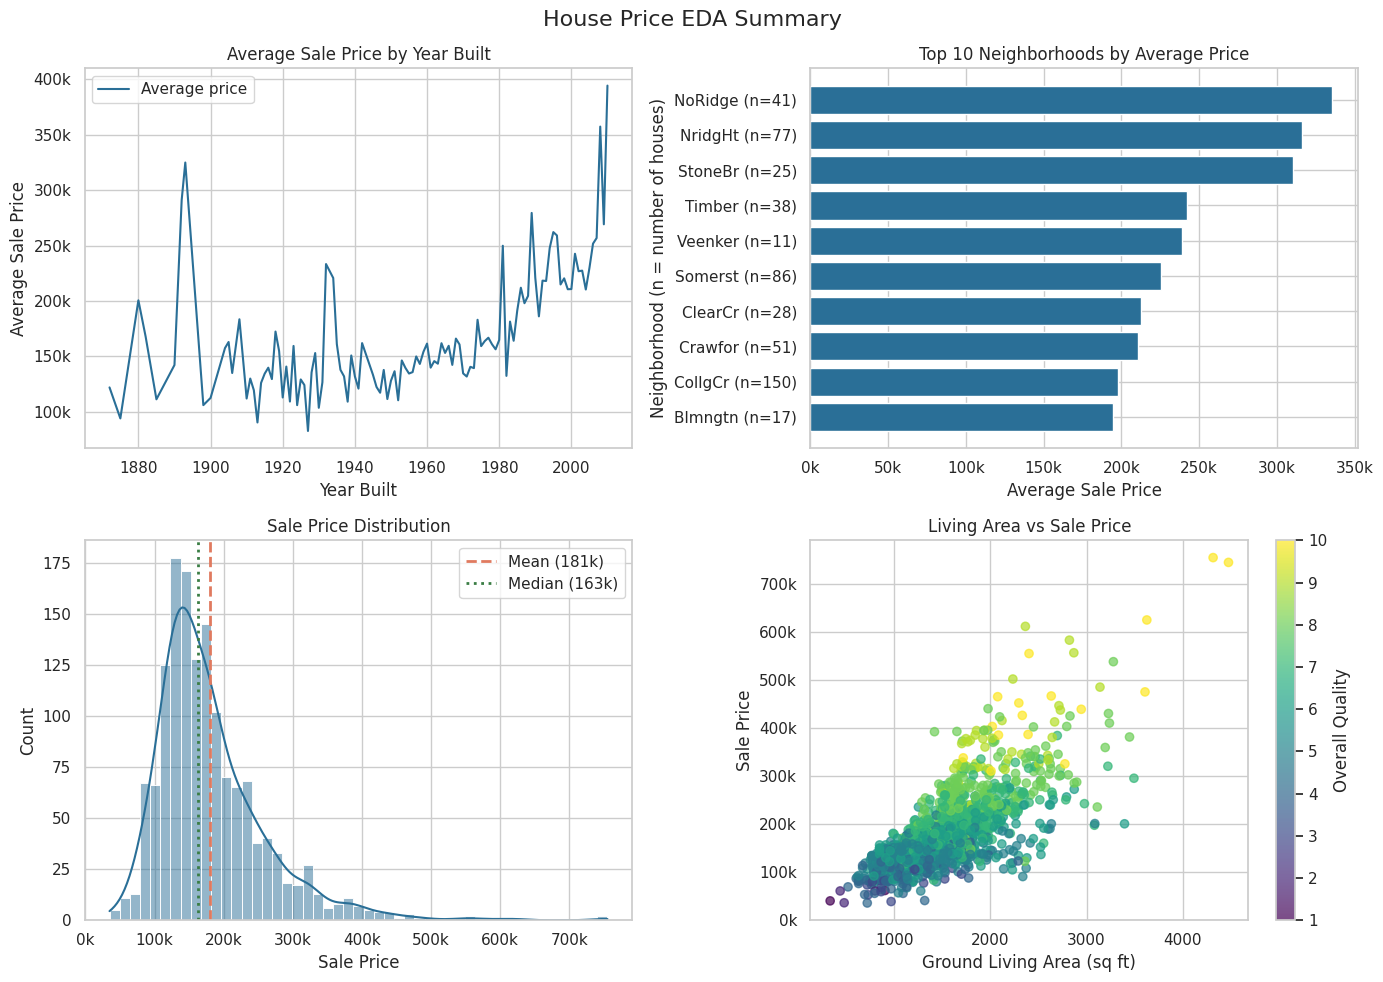

Dashboard saved successfully as eda_dashboard.png


In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Average price by year built (Matplotlib line plot)
year_price = df_clean.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(year_price.index, year_price.values, color=BASE, label="Average price")
axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].yaxis.set_major_formatter(thousands)
axes[0, 0].legend()

# Panel 2: Top 10 neighbourhoods (Matplotlib horizontal bars)
nb = df_clean.groupby("Neighborhood")["SalePrice"].agg(["mean", "count"])
top10_nb = nb.nlargest(10, "mean").sort_values("mean")
labels = [f"{name} (n={int(row['count'])})" for name, row in top10_nb.iterrows()]
axes[0, 1].barh(labels, top10_nb["mean"].values, color=BASE)
axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].set_ylabel("Neighborhood (n = number of houses)")
axes[0, 1].xaxis.set_major_formatter(thousands)

# Panel 3: Distribution with mean and median (Seaborn)
sns.histplot(df_clean["SalePrice"], kde=True, color=BASE, ax=axes[1, 0])
mean_price = df_clean["SalePrice"].mean()
median_price = df_clean["SalePrice"].median()
axes[1, 0].axvline(mean_price, color=ACCENT, linestyle="--", linewidth=2, label=f"Mean ({mean_price/1000:,.0f}k)")
axes[1, 0].axvline(median_price, color=GREEN, linestyle=":", linewidth=2, label=f"Median ({median_price/1000:,.0f}k)")
axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].xaxis.set_major_formatter(thousands)
axes[1, 0].legend()

# Panel 4: Living area vs price, coloured by quality
scatter = axes[1, 1].scatter(df_clean["GrLivArea"], df_clean["SalePrice"],
                             c=df_clean["OverallQual"], cmap="viridis", alpha=0.7)
axes[1, 1].set_title("Living Area vs Sale Price")
axes[1, 1].set_xlabel("Ground Living Area (sq ft)")
axes[1, 1].set_ylabel("Sale Price")
axes[1, 1].yaxis.set_major_formatter(thousands)
fig.colorbar(scatter, ax=axes[1, 1], label="Overall Quality")

fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

print("Dashboard saved successfully as eda_dashboard.png")

### What we learned

- Newer houses tend to sell for more, with a lot of year-to-year noise in the early decades where there are few houses per year.
- A handful of neighbourhoods clearly lead on average price. The `n =` in the labels warns us that averages based on few houses are less reliable.
- The mean sits to the right of the median, which is the right-skew from Step 3.
- In the scatter plot, colour moves from dark (low quality) to bright (high quality) as price rises, so **both size and quality push price up**.

## 11. Verifying the Expected Insights

The project asked us to **verify** six expected insights rather than assume them. The cell below recomputes each one from the data.

In [40]:
print("1. SalePrice is right skewed; log makes it near normal")
print(f"   skewness raw = {df['SalePrice'].skew():.2f} | log = {np.log1p(df['SalePrice']).skew():.2f}")

print("\n2. OverallQual and GrLivArea are among the strongest correlates")
print("   top 5:", top_corr.head(5).round(2).to_dict())

print("\n3. Price rises steadily with quality, spread is larger at the top")
print("   median rises at every grade:", df.groupby('OverallQual')['SalePrice'].median().is_monotonic_increasing)
print("   std at grade 5 vs 10:", round(q_std.loc[5]), "vs", round(q_std.loc[10]))

nb_med = df.groupby("Neighborhood")["SalePrice"].median().sort_values()
print("\n4. A few neighbourhoods have clearly higher medians")
print(f"   cheapest median = {nb_med.iloc[0]:,.0f} | most expensive median = {nb_med.iloc[-1]:,.0f}")
print("   top 3:", list(nb_med.index[-3:]))

print("\n5. A handful of very large, low-price houses distort trend lines")
no_out = df.drop(index=extreme_idx)
print(f"   houses found: {len(extreme_idx)} | corr(GrLivArea, SalePrice) with them: "
      f"{df['GrLivArea'].corr(df['SalePrice']):.3f} | without them: {no_out['GrLivArea'].corr(no_out['SalePrice']):.3f}")

print("\n6. Many apparent missing values are really 'feature absent'")
print(f"   columns with NA in raw data: {len(missing_table)} | of which 'feature absent': {len(absent) + 1}")

1. SalePrice is right skewed; log makes it near normal
   skewness raw = 1.88 | log = 0.12

2. OverallQual and GrLivArea are among the strongest correlates
   top 5: {'OverallQual': 0.79, 'GrLivArea': 0.71, 'GarageCars': 0.64, 'GarageArea': 0.62, 'TotalBsmtSF': 0.61}

3. Price rises steadily with quality, spread is larger at the top
   median rises at every grade: True
   std at grade 5 vs 10: 27107 vs 159785

4. A few neighbourhoods have clearly higher medians
   cheapest median = 88,000 | most expensive median = 315,000
   top 3: ['StoneBr', 'NoRidge', 'NridgHt']

5. A handful of very large, low-price houses distort trend lines
   houses found: 2 | corr(GrLivArea, SalePrice) with them: 0.709 | without them: 0.735

6. Many apparent missing values are really 'feature absent'
   columns with NA in raw data: 19 | of which 'feature absent': 15


## 12. Conclusion

In this project we performed Exploratory Data Analysis on the Ames Housing dataset (1460 houses, 81 columns) and answered the six guiding questions:

1. **Distribution of price:** `SalePrice` is right skewed (mean above median). A log transform brings it close to a normal shape.
2. **Strongest correlates:** overall quality (`OverallQual`) and living area (`GrLivArea`) lead, followed by garage, basement and bathroom size features.
3. **Quality and price:** price rises steadily with quality grade, and the spread of prices widens at the top grades.
4. **Neighbourhood:** a few neighbourhoods have clearly higher median prices than the rest.
5. **Outliers:** two very large, low-priced houses are *Partial* sales, so we treated them as unusual sales and removed them. Other high-price outliers are genuine and were kept.
6. **Missing values:** most missing values mean "feature absent" (pool, alley, fence, garage, basement...), so they were kept as `"None"`. Only a couple of columns were genuinely missing and were filled with documented rules.

We also found inconsistent spellings in the exterior-material columns and avoided a hidden trap where pandas reads the label `"None"` as a missing value.

### Limitations

- The data covers **one city (Ames, Iowa) in a short time window**, so conclusions may not apply to other markets.
- **Correlation is not causation**: size, quality and neighbourhood are linked to each other, so we cannot say how much any single factor adds to price.
- Pearson correlation only captures **linear** relationships.
- **Cleaning choices involve assumptions** (for example, filling `GarageYrBlt` with `YearBuilt`, and removing the two Partial sales). Different choices could change the numbers.
- Averages for **neighbourhoods with few houses** are less reliable.
- This is exploratory work only: no model was built, so we make **no predictions**.

## 13. Additional Analysis and Project Enhancements

This section adds practical comparisons that complement the original EDA. It still uses descriptive statistics and visualisation only; no machine-learning model is trained.

### 13.1 Quick project summary

A compact overview of the dataset, typical sale price, price range, and strongest numerical relationships.

In [41]:
summary = pd.DataFrame({
    "Metric": ["Number of houses", "Number of columns", "Average sale price",
               "Median sale price", "Minimum sale price", "Maximum sale price",
               "Average living area (sq ft)", "Median house quality"],
    "Value": [len(df_clean), df_clean.shape[1], df_clean["SalePrice"].mean(),
              df_clean["SalePrice"].median(), df_clean["SalePrice"].min(),
              df_clean["SalePrice"].max(), df_clean["GrLivArea"].mean(),
              df_clean["OverallQual"].median()]
})
display(summary)
print("Highest correlation with SalePrice:")
display(df_clean.select_dtypes(include=np.number).corr(numeric_only=True)["SalePrice"]
        .drop("SalePrice").sort_values(ascending=False).head(8).to_frame("Correlation"))

,Metric,Value
0,Number of houses,1458.000000
1,Number of columns,81.000000
2,Average sale price,180932.919067
3,Median sale price,163000.000000
4,Minimum sale price,34900.000000
5,Maximum sale price,755000.000000
6,Average living area (sq ft),1510.465706
7,Median house quality,6.000000


Highest correlation with SalePrice:


,Correlation
OverallQual,0.795774
GrLivArea,0.734968
TotalBsmtSF,0.651153
GarageCars,0.641047
1stFlrSF,0.631530
GarageArea,0.629217
FullBath,0.562165
TotRmsAbvGrd,0.537769


### 13.2 Price per square foot

Sale price divided by above-ground living area gives a simple size-adjusted comparison. This is an exploratory ratio, not a formal market valuation.

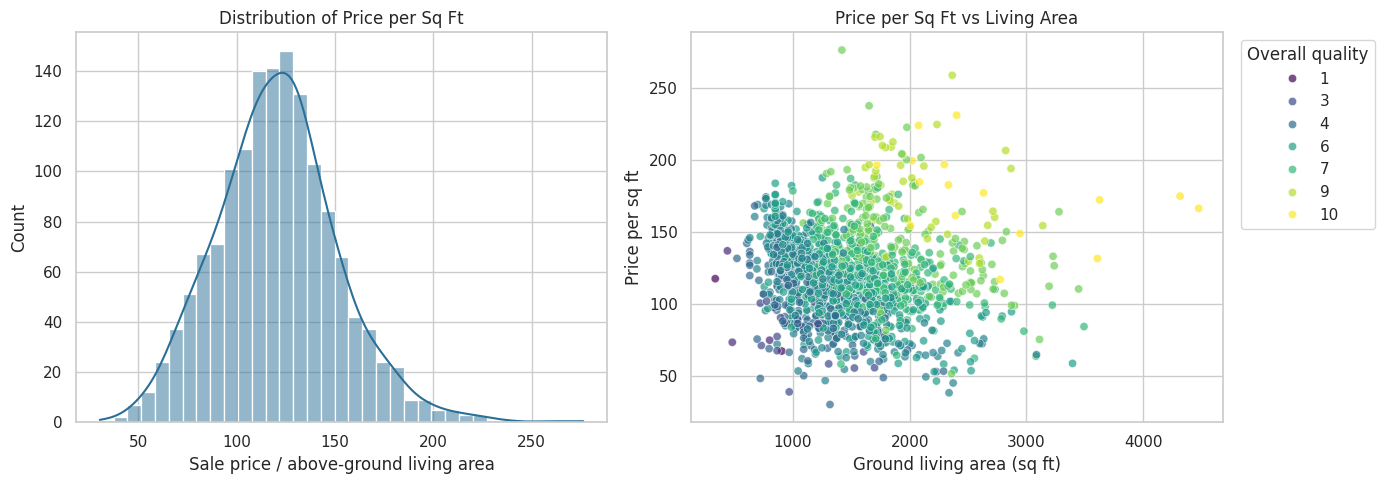

Median price per sq ft: 120.11
Mean price per sq ft:   120.69


In [42]:
price_area = df_clean.loc[df_clean["GrLivArea"] > 0].copy()
price_area["PricePerSqFt"] = price_area["SalePrice"] / price_area["GrLivArea"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(price_area["PricePerSqFt"], bins=35, kde=True, color=BASE, ax=axes[0])
axes[0].set_title("Distribution of Price per Sq Ft")
axes[0].set_xlabel("Sale price / above-ground living area")
sns.scatterplot(data=price_area, x="GrLivArea", y="PricePerSqFt",
                hue="OverallQual", palette="viridis", alpha=.7, ax=axes[1])
axes[1].set_title("Price per Sq Ft vs Living Area")
axes[1].set_xlabel("Ground living area (sq ft)")
axes[1].set_ylabel("Price per sq ft")
axes[1].legend(title="Overall quality", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"Median price per sq ft: {price_area['PricePerSqFt'].median():,.2f}")
print(f"Mean price per sq ft:   {price_area['PricePerSqFt'].mean():,.2f}")

### 13.3 Neighbourhood comparison with a minimum sample size

Neighbourhood averages can be misleading when only a few houses are present. This chart includes neighbourhoods with at least 10 cleaned sales and shows median prices.

,median,mean,count
Neighborhood,,,
NridgHt,"315,000","316,271",77
NoRidge,"301,500","335,295",41
StoneBr,"278,000","310,499",25
Timber,"228,475","242,247",38
Somerst,"225,500","225,380",86
Veenker,"218,000","238,773",11
Crawfor,"200,624","210,625",51
ClearCr,"200,250","212,565",28
CollgCr,"197,200","197,966",150


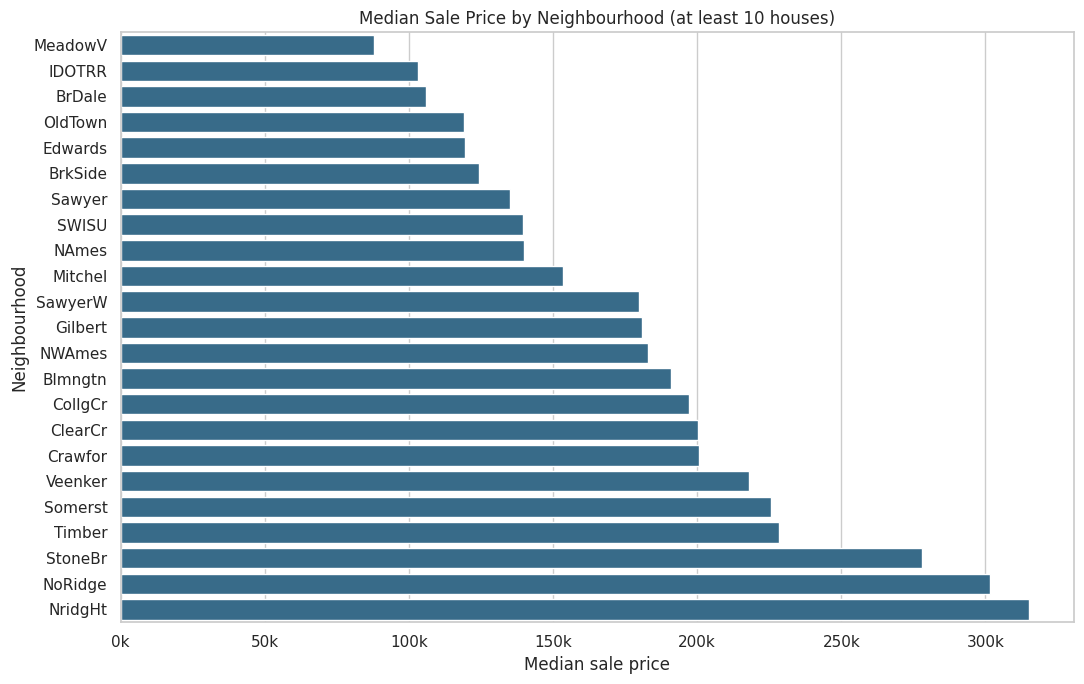

In [43]:
neighbourhood_stats = (df_clean.groupby("Neighborhood", observed=False)["SalePrice"]
                       .agg(["median", "mean", "count"])
                       .query("count >= 10")
                       .sort_values("median", ascending=False))
display(neighbourhood_stats.style.format({"median": "{:,.0f}", "mean": "{:,.0f}"}))

plt.figure(figsize=(11, 7))
plot_nb = neighbourhood_stats.sort_values("median")
sns.barplot(data=plot_nb.reset_index(), x="median", y="Neighborhood", color=BASE)
plt.title("Median Sale Price by Neighbourhood (at least 10 houses)")
plt.xlabel("Median sale price")
plt.ylabel("Neighbourhood")
plt.gca().xaxis.set_major_formatter(thousands)
plt.tight_layout()
plt.show()

### 13.4 Sale timing: year and season

This explores whether prices and sales volume vary by the year or month of sale. Seasonal groups are descriptive and do not establish why prices differ.

,YrSold,MedianSalePrice,NumberOfSales
0,2006,163995.0,314
1,2007,166000.0,328
2,2008,165000.0,303
3,2009,162000.0,338
4,2010,155000.0,175


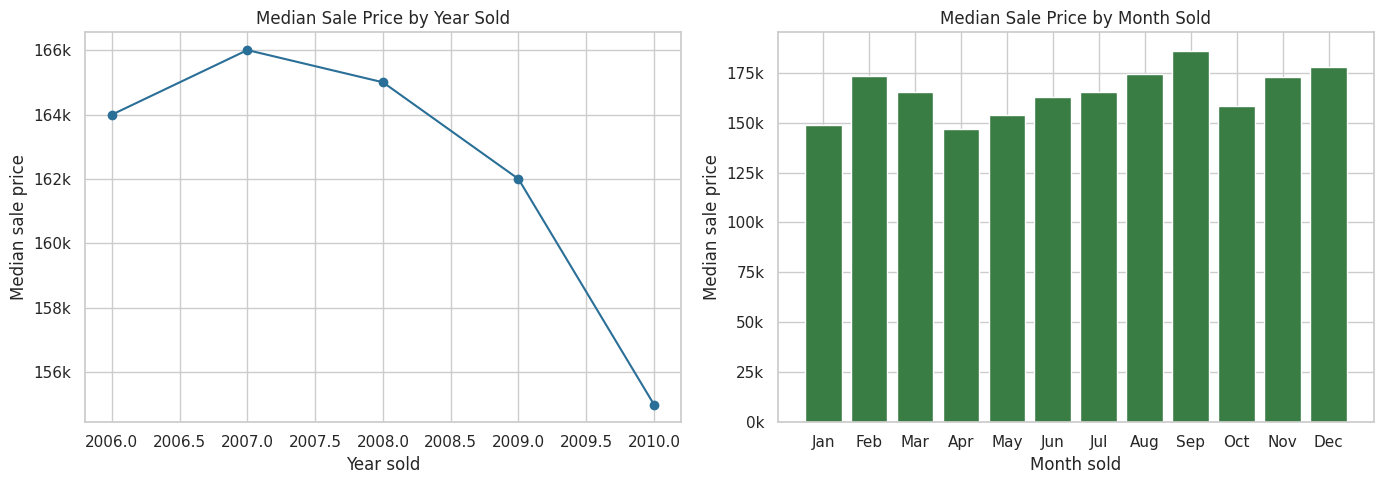

In [44]:
yearly_sales = df_clean.groupby("YrSold").agg(
    MedianSalePrice=("SalePrice", "median"),
    NumberOfSales=("SalePrice", "size")
).reset_index()
display(yearly_sales)

month_order = list(range(1, 13))
monthly_sales = (df_clean.groupby("MoSold")["SalePrice"]
                 .agg(["median", "count"]).reindex(month_order))
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(yearly_sales["YrSold"], yearly_sales["MedianSalePrice"],
             marker="o", color=BASE)
axes[0].set_title("Median Sale Price by Year Sold")
axes[0].set_xlabel("Year sold")
axes[0].set_ylabel("Median sale price")
axes[0].yaxis.set_major_formatter(thousands)
axes[1].bar(month_labels, monthly_sales["median"], color=GREEN)
axes[1].set_title("Median Sale Price by Month Sold")
axes[1].set_xlabel("Month sold")
axes[1].set_ylabel("Median sale price")
axes[1].yaxis.set_major_formatter(thousands)
plt.tight_layout()
plt.show()

### 13.5 Missing-value profile

The chart shows missing values in the original raw dataset. It is kept separate from the cleaned data so the original data-quality issue remains visible.

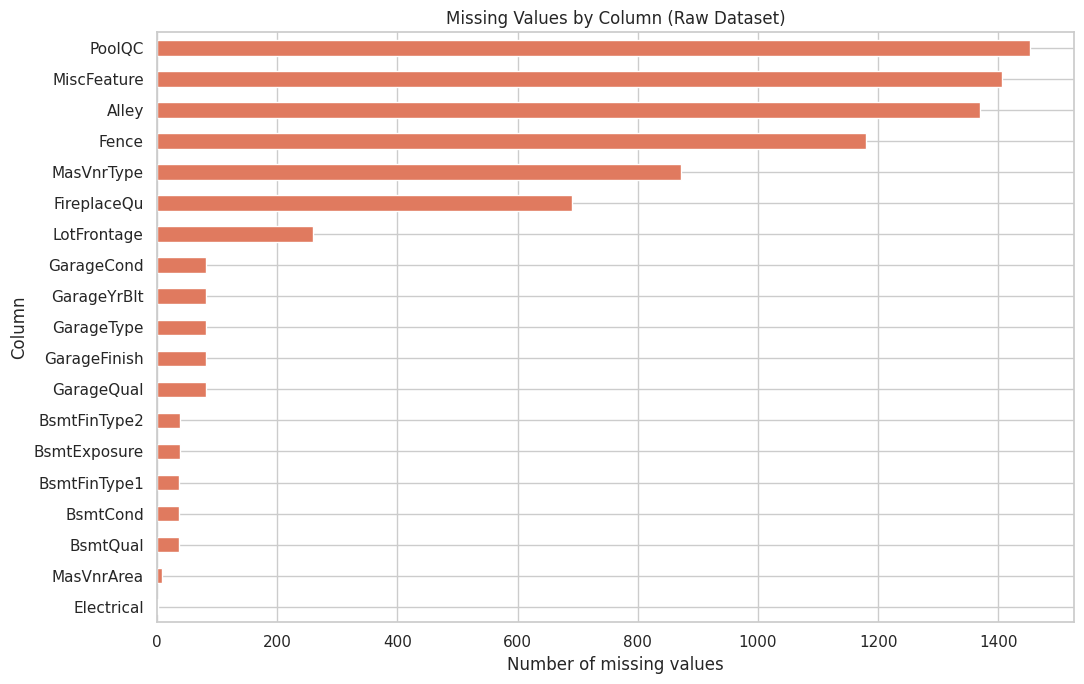

In [45]:
raw_missing = (df.isnull().sum().sort_values(ascending=False))
raw_missing = raw_missing[raw_missing > 0]
plt.figure(figsize=(11, 7))
raw_missing.sort_values().plot(kind="barh", color=ACCENT)
plt.title("Missing Values by Column (Raw Dataset)")
plt.xlabel("Number of missing values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

### 13.6 Export cleaned data and analysis tables

The following files are created in the notebook's current working directory. The raw dataset is never overwritten.

In [46]:
output_dir = Path.cwd()
cleaned_path = output_dir / "cleaned_house_prices.csv"
neighbourhood_path = output_dir / "neighbourhood_price_summary.csv"
correlation_path = output_dir / "saleprice_correlations.csv"

df_clean.to_csv(cleaned_path, index=False)
neighbourhood_stats.to_csv(neighbourhood_path)
(df_clean.select_dtypes(include=np.number)
 .corr(numeric_only=True)["SalePrice"]
 .drop("SalePrice").sort_values(ascending=False)
 .rename("Correlation").to_csv(correlation_path, header=True))

print("Export completed:")
for output_file in [cleaned_path, neighbourhood_path, correlation_path]:
    print(f"- {output_file.resolve()} ({output_file.stat().st_size:,} bytes)")

Export completed:
- /mnt/data/cleaned_house_prices.csv (482,145 bytes)
- /mnt/data/neighbourhood_price_summary.csv (878 bytes)
- /mnt/data/saleprice_correlations.csv (1,137 bytes)


## 14. Final Project Summary

The enhanced notebook now includes the original EDA workflow plus a compact project summary, price-per-square-foot analysis, a sample-size-aware neighbourhood comparison, sale timing analysis, a raw missing-value chart, and CSV exports.

**Important:** all comparisons are descriptive. Correlation and price-per-square-foot ratios do not prove that a feature causes a higher sale price, and the dataset represents homes sold in Ames, Iowa.